# Math 32 — Lecture 26: The Central Limit Theorem in Action — Averages and Sums

Companion notebook for Lecture 26. Every figure and simulation number in the slides is made here.

**How this notebook is organized.** Every code cell is **self-contained**: it re-imports what it needs, so you can
change a number (the number of customers `n`, the poll size, the seed, ...) and re-run just that cell.
Figures are saved in a `figures/` folder next to the notebook.

## 1. The coffee cart: the CLT for sums

Each customer spends $X_i$ dollars, with mean $\mu = \$3$ and standard deviation $\sigma = \$3$. We simulate the spending as
exponential (very skewed!), but the CLT only needs $\mu$ and $\sigma$. For $n = 100$ customers, the total is
$$S_{100} \approx N(n\mu,\ n\sigma^2) = N(300,\ 30^2).$$

The cell compares the simulation with the CLT answers from the slides: $P(S_{100} > 345) \approx 0.0668$,
$P(S_{100} > 240) \approx 0.9772$, and the 95th percentile $\approx 349.35$.

**Try it:** change `n` to `25` or `400`. Does the total still look like a bell? Is the CLT answer still close?

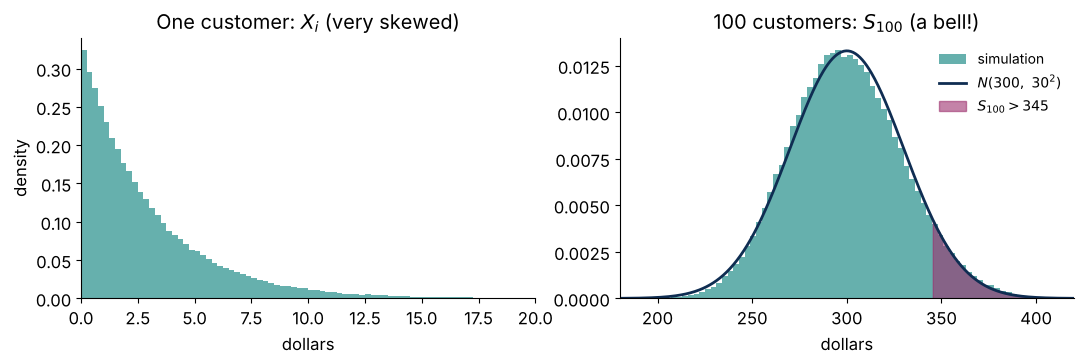

simulated P(S > 345) = 0.0720   (CLT: 0.0668)
simulated P(S > 240) = 0.9826   (CLT: 0.9772)
simulated 95th percentile = 350.96   (CLT: 349.35)


In [1]:
# Example 1: total spending of 100 coffee-cart customers (CLT for sums)
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from math import sqrt, pi

NAVY, GOLD, TEAL, MAGENTA, GRAY = "#0F2D52", "#DBAA01", "#007C77", "#9D316E", "#7A7A7A"
OUTDIR = Path("figures"); OUTDIR.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 12, "axes.spines.top": False, "axes.spines.right": False})

rng = np.random.default_rng(26)
reps, n, mu, sigma = 200_000, 100, 3.0, 3.0            # each customer: Exp with mean $3 (so sigma = $3)
X = rng.exponential(mu, size=(reps, n))
S = X.sum(axis=1)                                       # total for the day

fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
axs[0].hist(X[:, 0], bins=80, range=(0, 20), density=True, color=TEAL, alpha=0.6)
axs[0].set(xlim=(0, 20), xlabel="dollars", ylabel="density", title="One customer: $X_i$ (very skewed)")
s = np.linspace(180, 420, 400)
dens = np.exp(-(s - n * mu) ** 2 / (2 * n * sigma**2)) / sqrt(2 * pi * n * sigma**2)
axs[1].hist(S, bins=80, range=(180, 420), density=True, color=TEAL, alpha=0.6, label="simulation")
axs[1].plot(s, dens, color=NAVY, lw=2, label=r"$N(300,\ 30^2)$")
axs[1].fill_between(s, dens, where=s >= 345, color=MAGENTA, alpha=0.6, label=r"$S_{100} > 345$")
axs[1].set(xlim=(180, 420), xlabel="dollars", title="100 customers: $S_{100}$ (a bell!)")
axs[1].legend(frameon=False, loc="upper right", fontsize=10)
fig.tight_layout()
fig.savefig(OUTDIR / "clt_sum_coffee.png", dpi=200, facecolor="white", bbox_inches="tight")
plt.show()

print(f"simulated P(S > 345) = {np.mean(S > 345):.4f}   (CLT: 0.0668)")
print(f"simulated P(S > 240) = {np.mean(S > 240):.4f}   (CLT: 0.9772)")
print(f"simulated 95th percentile = {np.quantile(S, 0.95):.2f}   (CLT: 349.35)")

## 2. How close is a poll? The CLT for a proportion

A poll result $\hat p$ is the **average** of 0s and 1s (Bernoulli random variables), so the CLT gives
$$\hat p \approx N\!\left(p,\ \frac{p(1-p)}{n}\right).$$
With $p = 0.5$ and $n = 400$, the CLT says $P(0.45 \le \hat p \le 0.55) \approx 0.9544$.

**Try it:** change `n` to `100` or `1600`. What happens to the width of the bell?

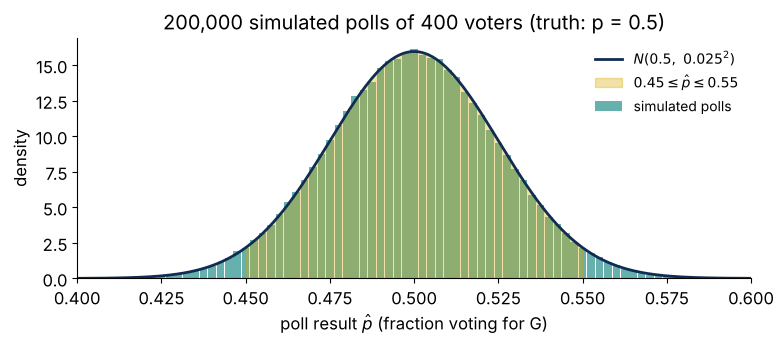

simulated P(0.45 <= phat <= 0.55) = 0.9589   (CLT: 0.9544)


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from math import sqrt, pi

NAVY, GOLD, TEAL, MAGENTA, GRAY = "#0F2D52", "#DBAA01", "#007C77", "#9D316E", "#7A7A7A"
OUTDIR = Path("figures"); OUTDIR.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 12, "axes.spines.top": False, "axes.spines.right": False})

# Example 2: a poll of n = 400 voters in a tied race (CLT for fractions)
rng = np.random.default_rng(27)
reps, n, p = 200_000, 400, 0.5
phat = rng.binomial(n, p, size=reps) / n                # fraction of "yes" in each simulated poll
sd = sqrt(p * (1 - p) / n)

fig, ax = plt.subplots(figsize=(8, 3.6))
vals, counts = np.unique(phat, return_counts=True)
ax.bar(vals, counts / reps * n, width=0.9 / n, color=TEAL, alpha=0.6, label="simulated polls")
x = np.linspace(0.4, 0.6, 400)
dens = np.exp(-(x - p) ** 2 / (2 * sd**2)) / sqrt(2 * pi * sd**2)
ax.plot(x, dens, color=NAVY, lw=2, label=r"$N(0.5,\ 0.025^2)$")
ax.fill_between(x, dens, where=(x >= 0.45) & (x <= 0.55), color=GOLD, alpha=0.35, label=r"$0.45 \leq \hat p \leq 0.55$")
ax.set(xlim=(0.4, 0.6), xlabel=r"poll result $\hat p$ (fraction voting for G)", ylabel="density",
       title="200,000 simulated polls of 400 voters (truth: p = 0.5)")
ax.legend(frameon=False, loc="upper right", fontsize=10)
fig.tight_layout()
fig.savefig(OUTDIR / "clt_poll.png", dpi=200, facecolor="white", bbox_inches="tight")
plt.show()

print(f"simulated P(0.45 <= phat <= 0.55) = {np.mean((phat >= 0.45) & (phat <= 0.55)):.4f}   (CLT: 0.9544)")

## 3. How many people should we poll?

For a 95% interval, the margin of error is $m = 1.96\sqrt{p(1-p)/n}$. Solving for $n$:
$$n \ \ge\ \left(\frac{1.96}{m}\right)^2 p(1-p) \qquad \text{(always round up!)}$$
The last lines check by simulation that a poll of $n = 2401$ is within $0.02$ of the truth about 95% of the time.

**Try it:** what $n$ do you need for a margin of $m = 0.01$? (Hint: about four times as many people.)

In [3]:
import math
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from math import sqrt, pi

NAVY, GOLD, TEAL, MAGENTA, GRAY = "#0F2D52", "#DBAA01", "#007C77", "#9D316E", "#7A7A7A"
OUTDIR = Path("figures"); OUTDIR.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 12, "axes.spines.top": False, "axes.spines.right": False})

# Example 3: how many people to poll?  margin m = 1.96*sqrt(p(1-p)/n)  =>  n = (1.96/m)^2 p(1-p)
for p in [0.5, 0.7]:
    m = 0.02
    n_exact = (1.96 / m) ** 2 * p * (1 - p)
    print(f"p = {p}: n = {n_exact:.2f}  -> poll {math.ceil(n_exact)} people")

# check by simulation: with n = 2401 and p = 0.5, how often is phat within 0.02 of p?
rng = np.random.default_rng(28)
phat = rng.binomial(2401, 0.5, size=200_000) / 2401
print(f"n = 2401: simulated P(|phat - 0.5| <= 0.02) = {np.mean(np.abs(phat - 0.5) <= 0.02):.4f}   (goal: 0.95)")

p = 0.5: n = 2401.00  -> poll 2401 people
p = 0.7: n = 2016.84  -> poll 2017 people
n = 2401: simulated P(|phat - 0.5| <= 0.02) = 0.9497   (goal: 0.95)
